1. Import Libraries and Load Dataset

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("fakenews.csv")

df.head()

,news_id,headline,body_text,source,label
0,1,Global economy faces recession,The Prime Minister attended the inauguration c...,CNN,Real
1,2,"Earthquake hits Chittagong, panic spreads",Government sources state that an official anno...,Daily Star,Real
2,3,Breakthrough in Bangladesh's tech industry,Local administration has visited the spot for ...,BBC,Fake
3,4,Dengue situation worsens in the country,The Prime Minister attended the inauguration c...,BBC,Fake
4,5,New virus outbreak sparks fear,Government sources state that an official anno...,Reuters,Real


2. Identify Common Publishing Sources

In [3]:
source_frequency = df['source'].value_counts()

print("Most Common Sources:")
print(source_frequency)

Most Common Sources:
source
CNN             476
Reuters         467
BBC             436
Unknown News    423
Daily Star      410
Name: count, dtype: int64


3. Compare Fake and Real News by Source

In [4]:
source_comparison = pd.crosstab(
    df['source'],
    df['label']
)

display(source_comparison)

label,Fake,Real
source,,
BBC,223,213
CNN,250,226
Daily Star,200,210
Reuters,241,226
Unknown News,196,227



4. Identify Sources Publishing Both Fake and Real News

In [5]:
source_comparison['Total'] = source_comparison.sum(axis=1)

source_comparison['Fake_Percentage'] = (
    source_comparison['Fake'] /
    source_comparison['Total'] * 100
)

source_comparison['Real_Percentage'] = (
    source_comparison['Real'] /
    source_comparison['Total'] * 100
)

display(source_comparison)

label,Fake,Real,Total,Fake_Percentage,Real_Percentage
source,,,,,
BBC,223,213,436,51.146789,48.853211
CNN,250,226,476,52.521008,47.478992
Daily Star,200,210,410,48.780488,51.219512
Reuters,241,226,467,51.605996,48.394004
Unknown News,196,227,423,46.335697,53.664303


5. Analyse Common Writing Patterns

In [6]:
df['headline_length'] = df['headline'].fillna('').apply(len)

df['body_length'] = df['body_text'].fillna('').apply(len)

writing_patterns = df.groupby('label').agg({
    'headline_length': 'mean',
    'body_length': 'mean'
})

display(writing_patterns)

,headline_length,body_length
label,,
Fake,37.123423,67.825225
Real,36.186933,66.969147


6. Identify Repeated Headlines Across Sources

In [7]:
repeated_headlines = df.groupby('headline').agg(
    article_count=('news_id', 'count'),
    source_count=('source', 'nunique'),
    sources=('source', lambda x: ', '.join(x.unique())),
    labels=('label', lambda x: ', '.join(x.unique()))
)

repeated_headlines = repeated_headlines[
    repeated_headlines['article_count'] > 1
]

display(repeated_headlines)

,article_count,source_count,sources,labels
headline,,,,
Bangladesh wins the World Cup,252,5,"Daily Star, Unknown News, CNN, BBC, Reuters","Real, Fake"
Bangladeshi astronaut captures photo from the moon,224,5,"Reuters, BBC, Daily Star, Unknown News, CNN","Real, Fake"
Breakthrough in Bangladesh's tech industry,226,5,"BBC, CNN, Reuters, Daily Star, Unknown News","Fake, Real"
Dengue situation worsens in the country,224,5,"BBC, Unknown News, Reuters, Daily Star, CNN","Fake, Real"
"Earthquake hits Chittagong, panic spreads",231,5,"Daily Star, Reuters, Unknown News, BBC, CNN","Real, Fake"
Global economy faces recession,218,5,"CNN, BBC, Unknown News, Daily Star, Reuters","Real, Fake"
Government announces major job reforms,194,5,"Unknown News, BBC, Daily Star, CNN, Reuters","Real, Fake"
New curriculum introduced in schools,205,5,"CNN, Unknown News, Daily Star, BBC, Reuters","Real, Fake"
New metro rail launched in Dhaka,223,5,"CNN, Daily Star, BBC, Unknown News, Reuters","Fake, Real"


7. Visualize Fake vs Real Publishing Patterns

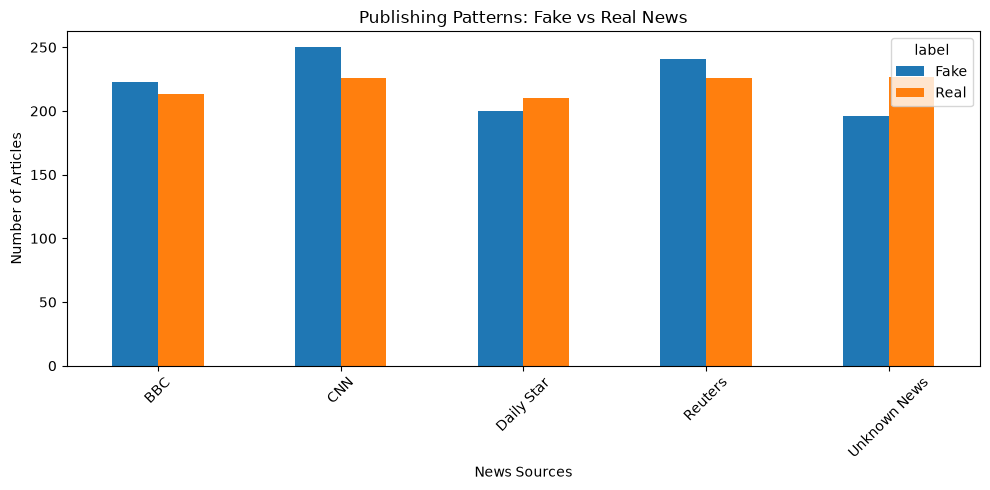

In [8]:
source_comparison[['Fake', 'Real']].plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title("Publishing Patterns: Fake vs Real News")
plt.xlabel("News Sources")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

8. Final Analysis

In [9]:
print("AUTHORSHIP AND DISINFORMATION PATTERN ANALYSIS")

print("\nMost Frequent Sources:")
print(source_frequency.head())

print("\nSources Publishing Both Fake and Real News:")
print(source_comparison[
    (source_comparison['Fake'] > 0) &
    (source_comparison['Real'] > 0)
])

print("\nRepeated Headlines:")
display(repeated_headlines)

print("\nWriting Pattern Comparison:")
display(writing_patterns)

AUTHORSHIP AND DISINFORMATION PATTERN ANALYSIS

Most Frequent Sources:
source
CNN             476
Reuters         467
BBC             436
Unknown News    423
Daily Star      410
Name: count, dtype: int64

Sources Publishing Both Fake and Real News:
label         Fake  Real  Total  Fake_Percentage  Real_Percentage
source                                                           
BBC            223   213    436        51.146789        48.853211
CNN            250   226    476        52.521008        47.478992
Daily Star     200   210    410        48.780488        51.219512
Reuters        241   226    467        51.605996        48.394004
Unknown News   196   227    423        46.335697        53.664303

Repeated Headlines:


,article_count,source_count,sources,labels
headline,,,,
Bangladesh wins the World Cup,252,5,"Daily Star, Unknown News, CNN, BBC, Reuters","Real, Fake"
Bangladeshi astronaut captures photo from the moon,224,5,"Reuters, BBC, Daily Star, Unknown News, CNN","Real, Fake"
Breakthrough in Bangladesh's tech industry,226,5,"BBC, CNN, Reuters, Daily Star, Unknown News","Fake, Real"
Dengue situation worsens in the country,224,5,"BBC, Unknown News, Reuters, Daily Star, CNN","Fake, Real"
"Earthquake hits Chittagong, panic spreads",231,5,"Daily Star, Reuters, Unknown News, BBC, CNN","Real, Fake"
Global economy faces recession,218,5,"CNN, BBC, Unknown News, Daily Star, Reuters","Real, Fake"
Government announces major job reforms,194,5,"Unknown News, BBC, Daily Star, CNN, Reuters","Real, Fake"
New curriculum introduced in schools,205,5,"CNN, Unknown News, Daily Star, BBC, Reuters","Real, Fake"
New metro rail launched in Dhaka,223,5,"CNN, Daily Star, BBC, Unknown News, Reuters","Fake, Real"



Writing Pattern Comparison:


,headline_length,body_length
label,,
Fake,37.123423,67.825225
Real,36.186933,66.969147
